# Density Estimation with Partial Differential Equation Regularization

fdaPDE Team, MOX, Department of Mathematics, Politecnico di Milano, Italy

`fdaPDE` (Palummo et al., 2025) is a C++ library with an interface to R for *physics-informed spatial and functional data analysis*, at the intersection of statistics and numerical analysis. The library provides advanced statistical methods designed for data located over complex spatial domains, ranging from irregular planar regions and curved surfaces to linear networks and volumes, possibly evolving over time. The class of methods implemented in `fdaPDE` features regularization terms based on Partial Differential Equations (PDEs), which allow incorporating information derived from the physics of the problem under study into the statistical modeling. This makes `fdaPDE` an extremely flexible tool for the analysis of complex data. For a review of this class of methods, refer to @sangalli2021spatial.

`fdaPDE` offers a wide range of modeling capabilities -- including regression, nonparametric
density estimation, functional data analysis, and more -- for data located over a spatial domain,
possibly evolving over time. Among the broad range of modeling capabilities offered by `fdaPDE`, we focus here on the **spatial density estimation method**.

## Model

Given *independent and identically distributed* point locations $\left\{\mathbf{p}_i\right\}_{i=1}^n \in \mathcal{D}$ observed on a *spatial domain* $\mathcal{D} \subset \mathbb{R}^2$, drawn from a common distribution $F$, we aim to estimate the corresponding *unknown probability density function* $f : \mathcal{D} \to \mathbb{R}^+$. Here, the spatial domain is a *planar region*, which may feature non-standard geometries, including irregular boundaries, concavities, and holes. The proposed density estimation method can accommodate also data observed on other types of spatial domains; examples include *linear networks* and *curved surfaces*.

For mathematical convenience, the estimation problem is reparameterized in terms of the log-density $g = \log f$. @ferraccioli2021nonparametric proposes to estimate $g$ as the minimizer of the following **penalized negative log-likelihood** $L(g)$:
$$ L(g) = -\frac{1}{n} \sum_{i=1}^n g(\mathbf{p}_i)+\int_\mathcal{D} e^{g(\mathbf{p})} \, \text{d} \mathbf{p} + \lambda \int_\mathcal{D} \left( \Delta g(\mathbf{p}) \right)^2 \, \text{d}\mathbf{p}\,. $$
The first term represents the *model fit* criterion. The second term ensures that $f$ is a *proper density* in $\mathcal{D}$. The third term is the **regularization term**, which encodes the *smoothness of the estimate*. The **smoothing parameter** $\lambda > 0$ balances the model adherence to the data with the regularity of the estimate. Extensions of this model to accommodate data observed on curved surfaces are described in @arnone2022roughness, while @begu2024nonparametric proposes the model for density estimation in the spatio-temporal framework.

The method for Density Estimation with Partial Differential Equation regularization for purely spatial point patterns, hereafter referred to as `DE-PDE`, is implemented within the newest version of the `fdaPDE` C++ library (Palummo et al., 2025). We load the library in the working environment as follows:

In [1]:
# Google Colab setup. Skip this cell when running locally.
if (any(nzchar(Sys.getenv(c(
  "COLAB_RELEASE_TAG",
  "COLAB_BACKEND_VERSION"
))))) {

  # Download the repository.
  repository <- "/content/course-materials"

  if (!dir.exists(repository)) {
    stopifnot(system2(
      "git",
      c(
        "clone", "--depth", "1",
        "https://github.com/fdaPDE/course-materials.git",
        shQuote(repository)
      )
    ) == 0L)
  }

  # Set the working directory and configure dependencies.
  setwd(file.path(
    repository,
    "courses",
    "[2026-Lancaster]-Physics-Informed-Statistical-Learning-for-Spatial-and-Functional-Data",
    "R", "notebook"
  ))

  source("../utils/colab_setup.R")
}

In [2]:
rm(list = ls())

# Import the fdaPDE library
# Load additional libraries and helper functions for plotting
suppressPackageStartupMessages({
    library(fdaPDE2)
    source("../utils/graphics.R")
  })

In [3]:
theme_set(theme_minimal() +
  theme(
    axis.title = element_text(),
    axis.text = element_text(),
    axis.ticks = element_line(),
    panel.grid = element_line()
  )
)

## Application to gastrointestinal infection data in Southampton (Hampshire county, UK)

As a benchmark application in epidemiology, we analyze cases of *non-specific gastrointestinal symptoms* reported to National Health Service (NHS) Direct in Hampshire County, United Kingdom, during the period from 2001 to 2003. The dataset, provided by @diggle2003line, comprises $9\,949$ locations where the event of interest was observed; see also @diggle2005point.

### 1. Spatial domain

To get the boundary of the spatial domain under consideration, we import the boundary nodes and segments from the files `../../data/DEPDE_2D/boundary_coords.txt` and `../../data/DEPDE_2D/boundary_coords.txt`.

In [4]:
## [SPATIAL DOMAIN]
# Load the boundary nodes
boundary_nodes <- read.table("../../data/DEPDE_2D/boundary_coords.txt")
names(boundary_nodes) <- c("lon", "lat")
head(boundary_nodes)

# Load the boundary segments
boundary_segments <- cbind(seq_len(nrow(boundary_nodes) - 1), 2:nrow(boundary_nodes))
boundary_segments <- rbind(boundary_segments, c(nrow(boundary_nodes), 1))

,lon,lat
,<dbl>,<dbl>
1,-1.4674,50.9102
2,-1.4587,50.9058
3,-1.4469,50.9035
4,-1.4394,50.9077
5,-1.4133,50.8991
6,-1.4082,50.8938


We use the `sf` [@pebesma2025sf] and `mapview` [@appelhans2025mapview] R packages to visualize the spatial domain interactively.

In [5]:
# Convert boundary into a sf object
boundary_nodes_sf <- st_as_sf(x = rbind(boundary_nodes, boundary_nodes[1,]), coords = c("lon", "lat"), crs = 4326)
boundary_polygon  <- st_polygon(list(st_coordinates(boundary_nodes_sf)))
boundary_sfc      <- st_sfc(geometry = boundary_polygon, crs = 4326)
boundary_sf       <- st_sf(geometry = boundary_sfc)

# Interactive plot
display_map(
    mapview(boundary_sf,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
        legend = FALSE, layer.name = "domain")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 1: Spatial domain of interest -- Southampton, Hampshire County, UK.
</div>

Now we build a **regular mesh** of the spatial domain under consideration. We create a mesh based on boundary nodes and segments, and then we refine it by setting the maximum element area to 0.00025 and the minimum angle to 20 degrees. To obtain the boundary nodes, we rely on the `sf` functionality, while the triangulation is constructed using the `RTriangle` [@shewchuk2025RTriangle] R package. Other software can be used to get the triangulation; for example, it can be constructed through the `fmesher` [@lindgren2025fmesher] R package.

In [6]:
## [MESH]
# Create a planar straight line graph object
boundary_pslg <- pslg(P = boundary_nodes, S = boundary_segments)

# Create a regular mesh of the spatial domain
mesh <- triangulate(p = boundary_pslg)
if (is.null(mesh$H)) mesh$H <- matrix(data = numeric(0), ncol = 2)

# Refine the mesh of the spatial domain
mesh <- triangulate(p = mesh, a = 0.0001, q = 20, D = TRUE)
if (is.null(mesh$H)) mesh$H <- matrix(data = numeric(0), ncol = 2)

# Number of nodes
nrow(mesh$P)
# Number of triangles
nrow(mesh$T)

[1] 4149

[1] 7692

We convert the `triangulation` object from `RTriangle` so that it can be read by `fdaPDE`.

In [7]:
# Set up the triangulation for fdaPDE
mesh <- triangulation(nodes = mesh$P, cells = mesh$T, boundary = mesh$PB)

In [8]:
# Nodes
head(mesh$nodes)

# Number of nodes
cat("Number of mesh nodes:", mesh$n_nodes)

-1.4674,50.9102
-1.4587,50.9058
-1.4469,50.9035
-1.4394,50.9077
-1.4133,50.8991
-1.4082,50.8938


Number of mesh nodes: 4149

In [9]:
# Edges
head(mesh$edges)

# Number of edges
cat("Number of mesh edges:", mesh$n_edges)

563,609
563,762
609,762
652,4145
652,922
922,4145


Number of mesh edges: 11840

In [10]:
# Triangles
head(mesh$cells)

# Number of triangles
cat("Number of mesh triangles:", mesh$n_cells)

563,609,762
652,4145,922
403,404,510
402,500,501
406,407,404
753,709,752


Number of mesh triangles: 7692

We visualize the resulting mesh of the spatial domain of interest.

In [11]:
# Interactive plot
display_map(
    mapview(boundary_sf,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
        legend = FALSE, layer = "domain") +
    mapview(mesh, crs = 4326,
          col.regions = "transparent", lwd = 1.25, legend = FALSE, layer = "mesh")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 2: Regular mesh of Southampton, Hampshire County, UK, with $4\,149$ nodes and $7\,692$ triangles.
</div>

We use the triangulation just created to define the spatial support of a `geoframe` object. This object will host layers containing data observed over the spatial support and code information in a format compatible with the implementation of the proposed density estimation method.

In [12]:
# Create the geoframe
hampshire <- geoframe(domain = mesh)
hampshire

Geoframe with 0 layers
Bounding box:    xmin: -1.9572 ymin: 50.7057 xmax: -0.7293 ymax: 51.3839
Number of nodes: 4149
Number of cells: 7692


### 2. Data

We briefly introduce the data under study. We add a data layer to the `geoframe` object defined above, thus obtaining a format compatible with the implementation of the proposed density estimation method. The layer contains the preprocessed data from the file `../../data/DEPDE_2D/data.txt`, loaded into the working environment as a `data.frame` object. To simplify the analysis, here we restrict our attention to the first $2\,500$ cases, corresponding to events recorded in 2001.

In [13]:
## [DATA]
# Load the data
data <- read.table(file = "../../data/DEPDE_2D/data.txt", header = TRUE)
head(data)

# Focus on cases occurred in 2001 (first 2500 cases)
data <- data[1:2500,]

# Add layer with data to the geoframe object
hampshire$insert(layer = "diseases", type = "point", geo = c("lon", "lat"), data = data)
hampshire

,lon,lat
,<dbl>,<dbl>
1,-1.101737,50.86110
2,-1.024927,50.89315
3,-1.025923,50.90321
4,-1.520984,50.91256
5,-1.185885,50.92669
6,-1.165196,50.92682


Geoframe with 1 layers
Bounding box:    xmin: -1.9572 ymin: 50.7057 xmax: -0.7293 ymax: 51.3839
Number of nodes: 4149
Number of cells: 7692

Layer: diseases
Type:  POINT PATTERN
Dims: 2500, 2

The recorded values are shown in the interactive plot below, created using the `mapview` [@appelhans2025mapview] R package. In this vignette,

In [14]:
# Interactive plot
display_map(
    mapview(hampshire[["diseases"]], varnames = "", crs = 4326, col.regions = "red3",
        cex = 2.5, layer.name = "locations") +
    mapview(boundary_sf,
         col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
         legend = FALSE, layer = "domain")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 3: Locations of non-specific gastrointestinal symptoms reported to National Health Service (NHS) Direct in Hampshire County, United Kingdom, in 2001.
</div>

### 3. Density estimation model fitting

We are ready to compute the `DE-PDE` density estimate using the `ppe` function. This function offers several options for solving the optimization problem -- here, we use the iterative Broyden–Fletcher–Goldfarb–Shanno (BFGS) optimization algorithm. For further information, see the documentation in the Help by typing `?ppe`. By default, the initial guess is estimated using the uniform distribution on the spatial region under consideration. In this example, for simplicity, we fix the value of the smoothing parameter to $0.01$ and perform a single fit.

In [15]:
## [DENSITY ESTIMATION]
# Proposed value for the smoothing parameter
lambda_fixed <- 1e-2

# Density estimation model
model <- ppe(data = hampshire)

# Density estimation fit
fit <- model$fit(
  lambda = lambda_fixed,
  optimizer = bfgs()
)

Typically, users have no prior knowledge about the optimal value of the smoothing parameter $\lambda\,.$ Hence, we are currently working on several calibrated techniques, including the $K$-fold cross-validation based on the $L^2$-norm of the error.

We print the density estimation model outputs.

In [16]:
# Density estimates at mesh nodes
cat("Density estimate at mesh nodes:", head(model$density))

# Log-density estimates at mesh nodes
cat("Log-density estimate at mesh nodes:", head(model$log_density))

Density estimate at mesh nodes: 5.703253e+81 2.964734e+73 0.3805663 7.85481e+145 5.937781e+164 9.175049e+61Log-density estimate at mesh nodes: 188.2504 169.1755 -0.966095 335.936 379.4053 142.6742

In [17]:
# Finite element function
f <- fe_function(domain =  mesh, type = "P1", coeff = model$log_density)

The density estimation model fit over the region of interest is instead displayed below.

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
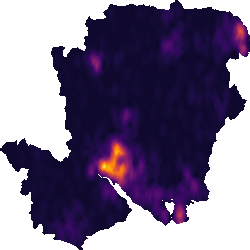

In [18]:
# Interactive plot
display_map(
    mapview(f, crs = 4326, col.regions = inferno,
        na.color = "transparent", layer.name = "ESTIMATE") +
    mapview(boundary_sf,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 2,
        legend = FALSE, layer.name = "domain")
)

<div style="text-align: center;">
Figure 4: `DE-PDE` density estimate. The values seems very high, but the domain area is very small.
</div>

The values in the figure above may appear very high because the coordinates are expressed in longitude and latitude, which results in a much smaller domain area than in reality. One may consider rescaling the values to account for this fact.

The irregular shape of the spatial domain influences the disease spread, resulting for instance in different behaviors along the western and eastern shores of the Southampton Water estuary. The method effectively captures this spatial pattern.

## References

<div id="refs" class="references csl-bib-body hanging-indent"
data-entry-spacing="0" data-line-spacing="2" role="list">
<div id="ref-appelhans2025mapview" class="csl-entry" role="listitem">
Appelhans, T., Detsch, F., Reudenbach, C., &amp; Woellauer, S. (2023).
<em>Mapview: <span>I</span>nteractive viewing of spatial data in
<span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=mapview"
class="uri">https://CRAN.R-project.org/package=mapview</a>.
</div>
<div id="ref-arnone2022roughness" class="csl-entry" role="listitem">
Arnone, E., Ferraccioli, F., Pigolotti, C., &amp; Sangalli, L. M.
(2022). A roughness penalty approach to estimate densities over
two-dimensional manifolds. <em>Computational Statistics &amp; Data
Analysis</em>, <em>174</em>. <a
href="https://doi.org/10.1016/j.csda.2022.107527">https://doi.org/10.1016/j.csda.2022.107527</a>
</div>
<div id="ref-begu2024nonparametric" class="csl-entry" role="listitem">
Begu, B., Panzeri, S., Arnone, E., Carey, M., &amp; Sangalli, L. M.
(2024). A nonparametric penalized likelihood approach to density
estimation of space-time point patterns. <em>Spatial Statistics</em>. <a
href="https://doi.org/10.1016/j.spasta.2024.100824">https://doi.org/10.1016/j.spasta.2024.100824</a>
</div>
<div id="ref-diggle2003line" class="csl-entry" role="listitem">
Diggle, P., Knorr-Held, L., Rowlingson, B., Su, T.-L., Hawtin, P., &amp;
Bryant, T. N. (2003). On-line monitoring of public health surveillance
data. In <em>Monitoring the health of populations</em> (pp. 233–266).
</div>
<div id="ref-diggle2005point" class="csl-entry" role="listitem">
Diggle, P., Rowlingson, B., &amp; Su, T. (2005). Point process
methodology for on-line spatio-temporal disease surveillance.
<em>Environmetrics</em>, <em>16</em>(5), 423–434.
</div>
<div id="ref-ferraccioli2021nonparametric" class="csl-entry"
role="listitem">
Ferraccioli, F., Arnone, E., Finos, L., Ramsay, J. O., &amp; Sangalli,
L. M. (2021). Nonparametric density estimation over complicated domains.
<em>Journal of the Royal Statistical Society Series B: Statistical
Methodology</em>, <em>83</em>(2), 346–368. <a
href="https://doi.org/10.1111/rssb.12415">https://doi.org/10.1111/rssb.12415</a>
</div>
<div id="ref-lindgren2025fmesher" class="csl-entry" role="listitem">
Lindgren, F. (2025). <em>Fmesher: <span>T</span>riangle meshes and
related geometry tools</em>. url: <a
href="https://CRAN.R-project.org/package=fmesher"
class="uri">https://CRAN.R-project.org/package=fmesher</a>.
</div>
<div id="ref-palummo2026fdapde" class="csl-entry" role="listitem">
Palummo, A., Clemente, A., Sangalli, E., Arnone, Formaggia, L., &amp;
Maria, L. (2025). <em>fdaPDE: <span>P</span>hysics-informed statistical
learning</em>. url: <a href="https://github.com/fdaPDE/fdaPDE-R"
class="uri">https://github.com/fdaPDE/fdaPDE-R</a>.
</div>
<div id="ref-pebesma2025sf" class="csl-entry" role="listitem">
Pebesma, E. (2025). <em>Sf: <span>S</span>imple <span>F</span>eatures
for <span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=sf"
class="uri">https://CRAN.R-project.org/package=sf</a>.
</div>
<div id="ref-sangalli2021spatial" class="csl-entry" role="listitem">
Sangalli, L. M. (2021). Spatial regression with partial differential
equation regularisation. <em>International Statistical Review</em>,
<em>89</em>(3), 505–531. <a
href="https://doi.org/10.1111/insr.12444">https://doi.org/10.1111/insr.12444</a>
</div>
<div id="ref-shewchuk2025RTriangle" class="csl-entry" role="listitem">
Shewchuk, J. R., &amp; Sterratt, D. C. (2025). <em>RTriangle - a
2<span>D</span> quality mesh generator and <span>D</span>elaunay
triangulator</em>. url: <a
href="https://CRAN.R-project.org/package=RTriangle"
class="uri">https://CRAN.R-project.org/package=RTriangle</a>.
</div>
</div>